# 06. Line movement

**Question.** Does the price move before tipoff contain information that the tipoff price missed?

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 10.3, which was committed before any result here was computed. All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots.csv`, main sample, prices at 24h, 6h, 1h and tipoff. Price `p_home`, outcome `home_win`.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

**Primary test.** d = 0 in the 24h model of section 3. It is one of the 8 primary tests of Stage 10. Its Holm adjusted p value is in `results/stage10_all_tests.csv`, written by notebook 10.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from IPython.display import display

import all_tests
from csv_io import write_csv
from line_movement import (PART, RESULTS_DIR, base_sample, bins_figure, distribution_figure,
                           load_wide, model_frame, models, move_bins, move_summary,
                           sample_counts, tests_table)
from stats_tools import B, SEED

RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. Sample

The sample is every main-sample game with a price at 24h and at tipoff. The move of a game is

move = logit(p at tipoff) − logit(p at 24h),

for the home side. A positive move means the home team's price rose between 24h before tipoff and tipoff.

In [2]:
wide = load_wide()
base = base_sample(wide)
counts = sample_counts(wide, base)
write_csv(counts, RESULTS_DIR / "line_movement_sample_counts.csv")
display(counts)

,group,games
0,main sample,1229
1,price at 24h and at tipoff,1222
2,"of those, price at 6h",1222
3,"of those, price at 1h",1222
4,"of those, max_spread at most 0.05 at all four ...",1165


1,222 of the 1,229 main-sample games have a price at 24h and at tipoff. The other 7 were listed less than 24 hours before tipoff. All 1,222 also have a price at 6h and at 1h, so the three models below use the same games. The spread filter keeps 1,165 of them.

## 2. How large are the moves (descriptive)

No test is attached to this section. The table describes the 24h move across games. The histogram uses bins of 0.1 on the log odds scale.

,24h move
n,1222.0000
mean,0.0241
sd,0.2505
min,-0.8613
p05,-0.3702
q25,-0.1111
median,0.0140
q75,0.1494
p95,0.4298
max,1.5064


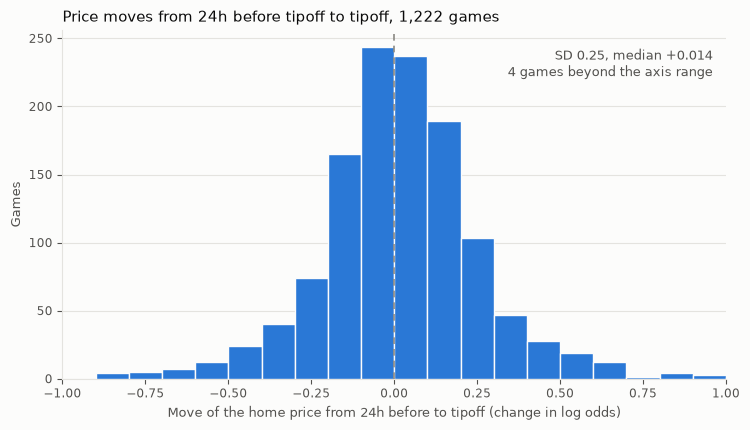

In [3]:
frame = model_frame(base, 24)
summary = move_summary(frame)
write_csv(summary, RESULTS_DIR / "line_movement_summary.csv")
display(summary.T.rename(columns={0: "24h move"}).round(4))
fig = distribution_figure(frame, RESULTS_DIR / "line_movement_distribution.png")

**Size.** The moves are small for most games. The standard deviation is 0.25 on the log odds scale. For a price near 50%, that is about 6 percentage points. Half of the games moved between -0.11 and +0.15, and nine in ten between -0.37 and +0.43. The mean absolute move is 0.18.

**Direction.** The moves are close to balanced: 53.0% of the games moved toward the home team, 45.4% toward the away team and 1.6% did not move. The mean is +0.024 and the median +0.014.

**Tails.** A few games moved a lot. The largest moves are -0.86 and +1.51, and 4 games lie beyond the range of the histogram.

## 3. The test

The model:

logit P(home win) = a + b · logit(p at tipoff) + d · move

Standard errors are clustered by home team. The test is d = 0.

- d = 0: the tipoff price already holds what the move says.
- d > 0: underreaction. The market did not move far enough.
- d < 0: overreaction. The market moved too far.

`boot_lo` and `boot_hi` are the 95% percentile interval from the block bootstrap by game date.

In [4]:
out = models(base)
logistic = pd.concat([o["logistic"] for o in out.values()], ignore_index=True)
bootstrap = pd.concat([o["bootstrap"] for o in out.values()], ignore_index=True)
effects = pd.concat([o["effects"] for o in out.values()], ignore_index=True)
write_csv(logistic, RESULTS_DIR / "line_movement_logistic.csv")
write_csv(bootstrap, RESULTS_DIR / "line_movement_bootstrap.csv")
write_csv(effects, RESULTS_DIR / "line_movement_effects.csv")
display(logistic[logistic["model"] == "24h"].round(4))

,model,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters,boot_lo,boot_hi
0,24h,intercept_a,0.0164,0.0464,-0.0746,0.1074,0.0,0.3529,0.7241,1222,30,-0.1011,0.1397
1,24h,slope_b,1.0052,0.0652,0.8775,1.1329,1.0,0.0800,0.9363,1222,30,0.8779,1.1637
2,24h,move_d,0.3883,0.2561,-0.1136,0.8903,0.0,1.5165,0.1294,1222,30,-0.1773,0.9581


**d.** The estimate is d = 0.388, with clustered SE 0.256 (z = 1.52, p = 0.13). The clustered 95% interval is -0.114 to 0.890 and the bootstrap interval is -0.177 to 0.958. Both contain 0.

**What this means.** The estimate is positive, which is the direction of underreaction. But it is not distinguishable from 0, so the test does not reject that the tipoff price already holds what the move says. The interval is wide. It leaves room for no effect and for a sizeable one.

**a and b.** a = 0.016 (p = 0.72) and b = 1.005 (p = 0.94). With the move in the model, the tipoff price is still calibrated as in Stage 8.

## 4. The size of d in plain terms

`move_sd` is the standard deviation of the move across games. `d_per_sd` is d times that. `avg_effect_per_sd` is the average change in the home team's fitted win probability when the move is one standard deviation larger and the tipoff price stays the same. The bootstrap keeps the step at the full-sample standard deviation in every replicate.

In [5]:
display(effects[effects["model"] == "24h"].round(4))

,model,move_sd,move_d,d_per_sd,d_per_sd_boot_lo,d_per_sd_boot_hi,avg_effect_per_sd,avg_effect_boot_lo,avg_effect_boot_hi
0,24h,0.2505,0.3883,0.0973,-0.0444,0.24,0.0188,-0.0085,0.0455


One standard deviation of the 24h move is 0.25. A move one SD larger adds 0.097 to the log odds of a home win at the same tipoff price (bootstrap -0.044 to 0.240). On average that is 1.9 percentage points of win probability (bootstrap -0.9 to 4.6 points). The interval contains 0.

## 5. Secondary models

The same model with the move from 6h to tipoff and from 1h to tipoff, on the same games, and the 24h model after the spread filter of plan 9.2 (every game whose `max_spread` is above 0.05 or missing at any of the four horizons is dropped). These are secondary tests.

In [6]:
display(logistic[logistic["term"] == "move_d"].round(4))
display(effects.round(4))

,model,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters,boot_lo,boot_hi
2,24h,move_d,0.3883,0.2561,-0.1136,0.8903,0.0,1.5165,0.1294,1222,30,-0.1773,0.9581
5,6h,move_d,0.3431,0.5241,-0.6842,1.3703,0.0,0.6545,0.5128,1222,30,-0.5216,1.3151
8,1h,move_d,0.0950,0.8728,-1.6157,1.8056,0.0,0.1088,0.9134,1222,30,-1.7126,2.0934
11,24h_spread_filter,move_d,0.3742,0.2605,-0.1363,0.8847,0.0,1.4367,0.1508,1165,30,-0.2300,0.9897


,model,move_sd,move_d,d_per_sd,d_per_sd_boot_lo,d_per_sd_boot_hi,avg_effect_per_sd,avg_effect_boot_lo,avg_effect_boot_hi
0,24h,0.2505,0.3883,0.0973,-0.0444,0.2400,0.0188,-0.0085,0.0455
1,6h,0.1488,0.3431,0.0510,-0.0776,0.1957,0.0099,-0.0153,0.0375
2,1h,0.0755,0.0950,0.0072,-0.1294,0.1581,0.0014,-0.0247,0.0298
3,24h_spread_filter,0.2468,0.3742,0.0924,-0.0568,0.2443,0.0176,-0.0110,0.0457


- **6h to tipoff.** d = 0.343 (SE 0.524, p = 0.51).
- **1h to tipoff.** d = 0.095 (SE 0.873, p = 0.91).
- **24h, after the spread filter (1,165 games).** d = 0.374 (SE 0.261, p = 0.15), close to the 0.388 of the main model.

None of them is distinguishable from 0. The later moves are smaller (SD 0.15 from 6h and 0.08 from 1h, against 0.25 from 24h), so their d is estimated with much less precision. In plain terms the effects are 1.0 point (6h) and 0.1 point (1h) per SD, with intervals that contain 0.

## 6. Win rate against the tipoff price, by size of the move (descriptive)

The games are sorted by the 24h move and cut into 10 equal-count bins. For each bin the plot shows the home-win rate minus the mean tipoff price. If the tipoff price is right whatever the move was, every point is near 0. The bar is the Wilson interval of the win rate, shifted by the mean tipoff price. No test is attached.

,bin,n,move_min,move_max,mean_move,mean_p_tipoff,home_wins,win_rate,win_rate_minus_price,wilson_lo_minus_price,wilson_hi_minus_price
0,1,123,-0.8613,-0.2537,-0.4171,0.4064,43,0.3496,-0.0568,-0.1353,0.0309
1,2,122,-0.2503,-0.1468,-0.1882,0.4565,56,0.4590,0.0025,-0.0833,0.0908
2,3,122,-0.1463,-0.0801,-0.1117,0.4869,68,0.5574,0.0705,-0.0180,0.1556
3,4,122,-0.0799,-0.0289,-0.0540,0.5302,58,0.4754,-0.0548,-0.1413,0.0332
4,5,122,-0.0282,0.0140,-0.0057,0.5534,69,0.5656,0.0121,-0.0765,0.0968
5,6,123,0.0141,0.0709,0.0447,0.5433,59,0.4797,-0.0636,-0.1499,0.0239
6,7,122,0.0711,0.1204,0.0949,0.5933,78,0.6393,0.0460,-0.0422,0.1258
7,8,122,0.1206,0.1828,0.1512,0.5857,74,0.6066,0.0208,-0.0678,0.1030
8,9,122,0.1828,0.2952,0.2341,0.6343,81,0.6639,0.0297,-0.0580,0.1074
9,10,122,0.2965,1.5064,0.4961,0.7168,92,0.7541,0.0373,-0.0461,0.1052


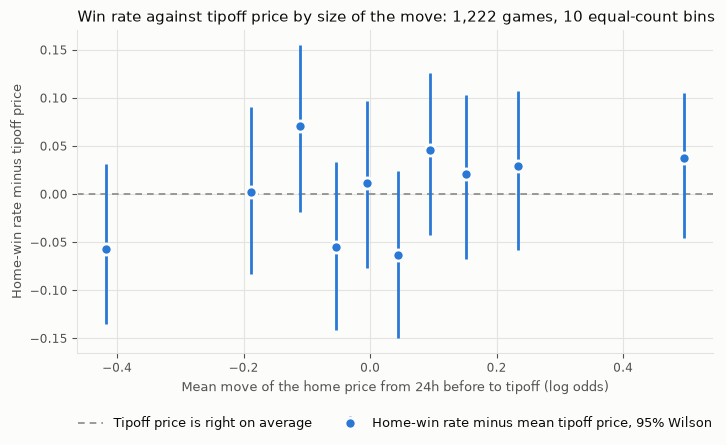

In [7]:
bins = move_bins(frame)
write_csv(bins, RESULTS_DIR / "line_movement_bins.csv")
display(bins.round(4))
fig = bins_figure(bins, len(frame), RESULTS_DIR / "line_movement_bins.png")

The differences run from -6.4 to +7.0 percentage points, and every interval contains 0.

The bin with the largest moves away from the home team is below 0 (-5.7 points), and the four bins with the largest moves toward the home team are all above 0 (+2.1 to +4.6 points). That is the pattern a positive d would give. The bins in between go both ways, the largest two differences among them have opposite signs, and no single bin is distinguishable from 0. This plot is descriptive and carries no test.

## 7. All tests of this notebook

Every Wald test above in the common Stage 10 layout. `p_bound` is min(1, 8 · p) for the primary test: the Holm adjusted p value across the 8 primary tests of Stage 10 can never be above it. The Holm value itself needs all 8 tests and is added by notebook 10.

In [8]:
tests = tests_table(logistic)
write_csv(tests, all_tests.part_path(PART))
shown = tests[["test_id", "role", "n", "estimate", "ci_lo", "ci_hi", "boot_lo", "boot_hi",
               "p_raw"]].copy()
shown["p_bound"] = all_tests.bonferroni_bound(shown["p_raw"]).where(shown["role"] == "primary")
display(shown.round(4))

,test_id,role,n,estimate,ci_lo,ci_hi,boot_lo,boot_hi,p_raw,p_bound
0,line_move_24h_a,secondary,1222,0.0164,-0.0746,0.1074,-0.1011,0.1397,0.7241,NaN
1,line_move_24h_b,secondary,1222,1.0052,0.8775,1.1329,0.8779,1.1637,0.9363,NaN
2,line_move_24h_d,primary,1222,0.3883,-0.1136,0.8903,-0.1773,0.9581,0.1294,1.0
3,line_move_6h_a,secondary,1222,0.0188,-0.0710,0.1086,-0.0965,0.1418,0.6813,NaN
4,line_move_6h_b,secondary,1222,1.0308,0.9081,1.1534,0.9033,1.1865,0.6231,NaN
5,line_move_6h_d,secondary,1222,0.3431,-0.6842,1.3703,-0.5216,1.3151,0.5128,NaN
6,line_move_1h_a,secondary,1222,0.0166,-0.0728,0.1061,-0.1009,0.1391,0.7157,NaN
7,line_move_1h_b,secondary,1222,1.0342,0.9124,1.1559,0.9071,1.1963,0.5822,NaN
8,line_move_1h_d,secondary,1222,0.0950,-1.6157,1.8056,-1.7126,2.0934,0.9134,NaN
9,line_move_24h_spread_filter_a,secondary,1165,0.0079,-0.0887,0.1045,-0.1139,0.1363,0.8725,NaN


**Primary test.** `line_move_24h_d` has p = 0.129. Its bound 8 · p is 1, so it cannot be significant after the Holm adjustment, whatever the other primary tests give.

**Secondary tests.** None of the 11 has a p value below 0.05.

**In short.** This season's data do not show that the move from 24h to tipoff carries information the tipoff price missed. The estimate points toward underreaction, and the data cannot tell a moderate underreaction from none.